   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  
Brier Score 0.1682


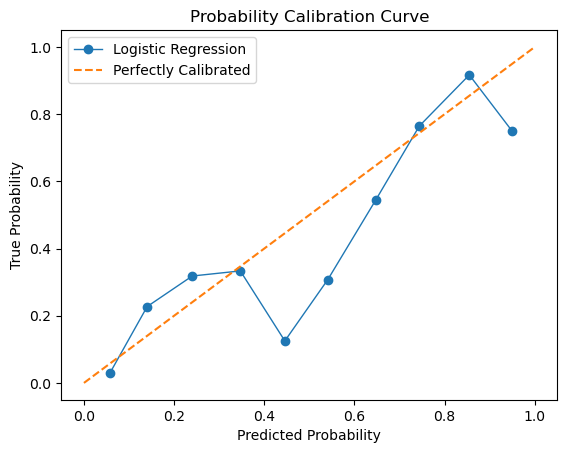

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import brier_score_loss
from sklearn.calibration import calibration_curve
import matplotlib.pyplot as plt


import random
np.random.seed(42)
df = pd.read_csv("C:/Users/angel_bothra.sias24_/Downloads/diabetes.csv")
print(df.head())

# x will be the 8 features
# y will be the outcome

X = df.drop(columns=['Outcome'])
y = df['Outcome']

# Split and scale data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

model = LogisticRegression(max_iter=1000)
model.fit(X_train_scaled, y_train)

# Accuracy on clean data
y_prob = model.predict_proba(X_test_scaled)[:,1]

brier = brier_score_loss(y_test, y_prob)
print(f"Brier Score {brier:.4f}")

prob_true, prob_pred = calibration_curve(y_test, y_prob, n_bins = 10)

#Plot the Probabilities Calibrated curve
plt.plot(prob_pred,
         prob_true,
         marker='o',
         linewidth=1,
         label='Logistic Regression')

#Plot the Perfectly Calibrated by Adding the 45-degree line to the plot
plt.plot([0, 1],
         [0, 1],
         linestyle='--',
         label='Perfectly Calibrated')


# Set the title and axis labels for the plot
plt.title('Probability Calibration Curve')
plt.xlabel('Predicted Probability')
plt.ylabel('True Probability')

# Add a legend to the plot
plt.legend(loc='best')

# Show the plot
plt.show()


if point is above line, model is underconfident
if point is under the line, the model is overconfident